In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns
from scipy.stats import mstats
import scipy.stats as stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.anova import anova_lm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
import warnings
warnings.filterwarnings("ignore")
sns.set_style('whitegrid')

In [2]:
hi = pd.read_csv('/kaggle/input/regression-dataset-for-household-income-analysis/data.csv')

In [3]:
hi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Age                             10000 non-null  int64 
 1   Education_Level                 10000 non-null  object
 2   Occupation                      10000 non-null  object
 3   Number_of_Dependents            10000 non-null  int64 
 4   Location                        10000 non-null  object
 5   Work_Experience                 10000 non-null  int64 
 6   Marital_Status                  10000 non-null  object
 7   Employment_Status               10000 non-null  object
 8   Household_Size                  10000 non-null  int64 
 9   Homeownership_Status            10000 non-null  object
 10  Type_of_Housing                 10000 non-null  object
 11  Gender                          10000 non-null  object
 12  Primary_Mode_of_Transportation  10000 non-null 

In [4]:
hi.head()

,Age,Education_Level,Occupation,Number_of_Dependents,Location,Work_Experience,Marital_Status,Employment_Status,Household_Size,Homeownership_Status,Type_of_Housing,Gender,Primary_Mode_of_Transportation,Income
0,56,Master's,Technology,5,Urban,21,Married,Full-time,7,Own,Apartment,Male,Public transit,72510
1,69,High School,Finance,0,Urban,4,Single,Full-time,7,Own,Apartment,Male,Biking,75462
2,46,Bachelor's,Technology,1,Urban,1,Single,Full-time,7,Own,Single-family home,Female,Car,71748
3,32,High School,Others,2,Urban,32,Married,Full-time,1,Own,Apartment,Female,Car,74520
4,60,Bachelor's,Finance,3,Urban,15,Married,Self-employed,4,Own,Townhouse,Male,Walking,640210


In [5]:
print('highest income: ', np.max(hi['Income']))
print('lowest income: ', np.min(hi['Income']))

highest income:  9992571
lowest income:  31044


In [6]:
numerical_features = ['Number_of_Dependents', 'Work_Experience', 'Household_Size', 'Age']


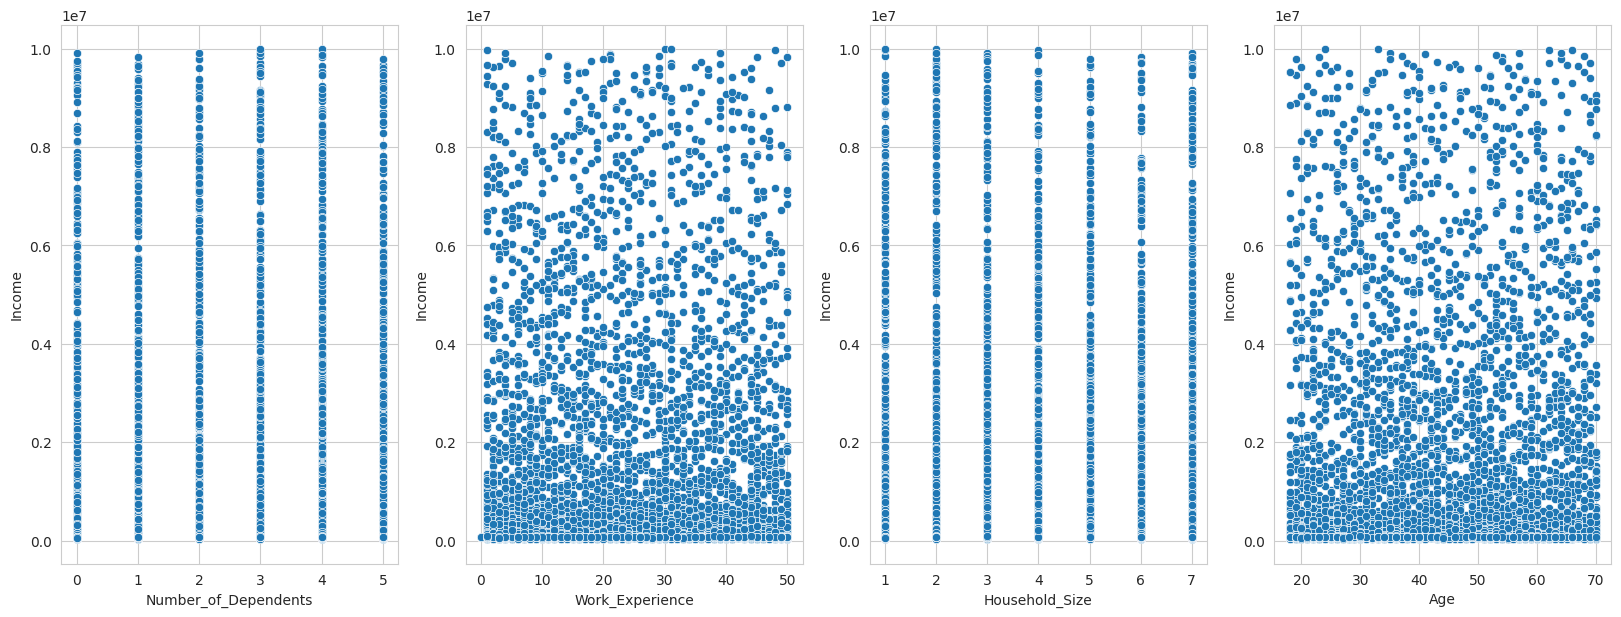

In [7]:
fig, ax = plt.subplots(1,4, figsize = (20,7))

for i, col in enumerate(hi[numerical_features]):
    sns.scatterplot(x = hi[col], y = hi['Income'], ax = ax[i])

Given the relationship between Income and the numeric features Number_of_Dependents, Work Experience, Household_Size, and age, it is obvious that there is no correlaton with Income.  Based on experience, one can conclude that these numeric variables will also be hypothesized as non-significant.

In [8]:
#model testing

lm = smf.ols('Income ~ C(Education_Level) + C(Occupation) + C(Location) + C(Marital_Status) \
                  + C(Employment_Status) +C(Homeownership_Status)+ C(Type_of_Housing) \
                    + C(Gender)', data = hi).fit()

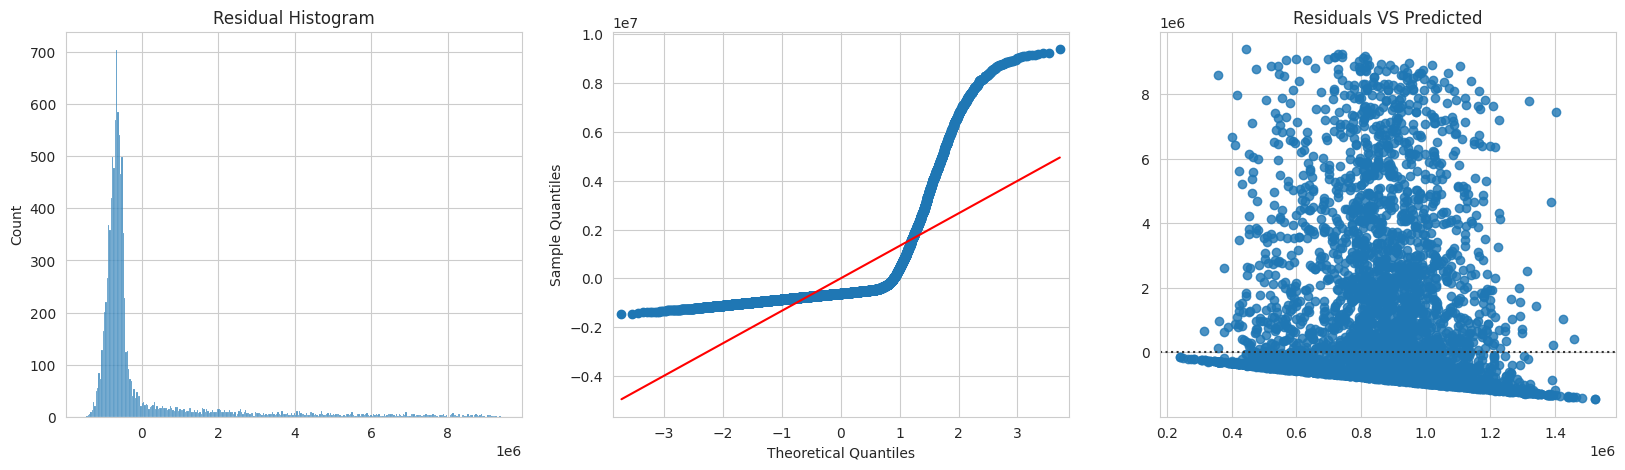

In [9]:

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

sns.histplot(lm.resid, ax=ax[0])
ax[0].set_title('Residual Histogram')

sm.qqplot(lm.resid, line='r', ax=ax[1])

sns.residplot(x=lm.fittedvalues, y=lm.resid, ax=ax[2])
ax[2].set_title('Residuals VS Predicted')

plt.show()


In [10]:
dw = durbin_watson(lm.resid)
_,jbpval,_,_ =  jarque_bera(lm.resid)
_,hppval,_,_ = het_breuschpagan(lm.resid, lm.model.exog)

if dw > 1.5:
    print('No autocorrelation.')
else:
    print('Autoccorelation is present.')
if jbpval < 0.05 and round(np.mean(lm.resid)) == 0:
    print('Residuals are not completely normal, but mean of residuals is approximately zero.')
else:
    print('Residuals are nornmal.')
if hppval < 0.05:
    print('Heteroskedasticity')
else:
    print('Homoskedasticity')

No autocorrelation.
Residuals are not completely normal, but mean of residuals is approximately zero.
Heteroskedasticity


In [11]:
lm2 = smf.ols('Income ~ C(Education_Level)+ C(Occupation) + C(Marital_Status) \
+ C(Employment_Status)+ C(Type_of_Housing)+ C(Gender)', data = hi).fit()

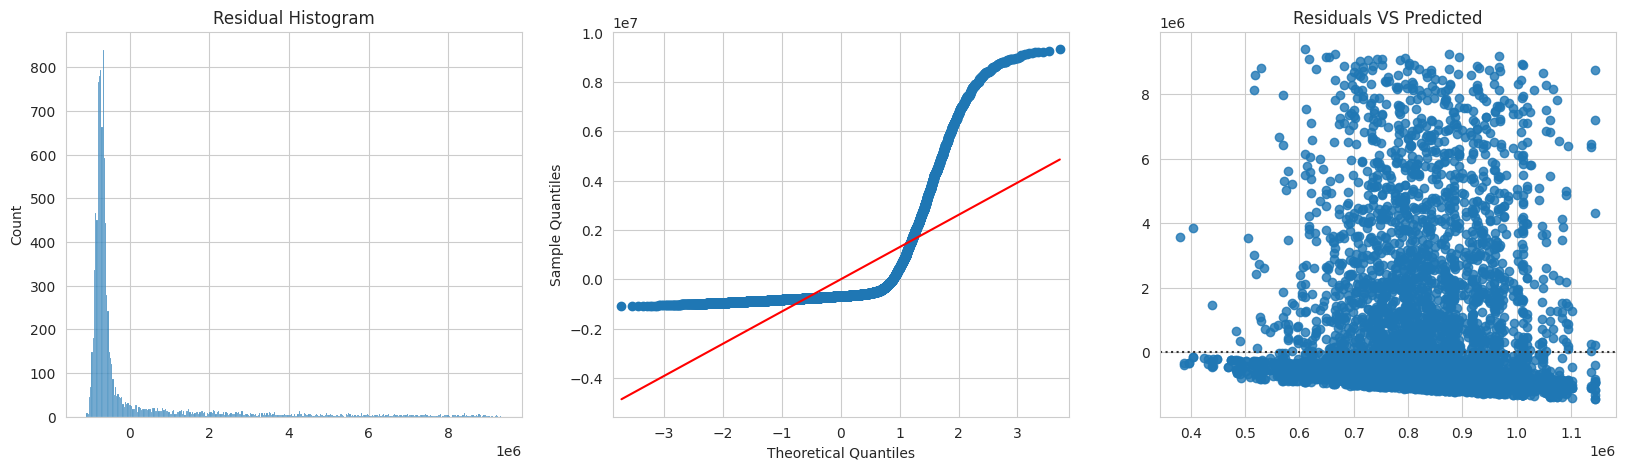

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

sns.histplot(lm2.resid, ax=ax[0])
ax[0].set_title('Residual Histogram')

sm.qqplot(lm2.resid, line='r', ax=ax[1])

sns.residplot(x=lm2.fittedvalues, y=lm.resid, ax=ax[2])
ax[2].set_title('Residuals VS Predicted')

plt.show()

In [13]:
dw = durbin_watson(lm2.resid)
_,jbpval,_,_ =  jarque_bera(lm2.resid)
_,hppval,_,_ = het_breuschpagan(lm2.resid, lm2.model.exog)

if dw > 1.5:
    print('No autocorrelation.')
else:
    print('Autoccorelation is present.')
if jbpval < 0.05 and round(np.mean(lm.resid)) == 0:
    print('Residuals are not completely normal, but mean of residuals is approximately zero.')
else:
    print('Residuals are nornmal.')
if hppval < 0.05:
    print('Heteroskedasticity')
else:
    print('Homoskedasticity')

No autocorrelation.
Residuals are not completely normal, but mean of residuals is approximately zero.
Homoskedasticity


After testing the model through trial and error, the two variables (Location and Homeownership) caused the model to be heteroskedastic so they were removed. The final model is lm2 which meets all assumptions of linear regression. Notice that all the variables in the model are categorical

In [14]:
lm2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Income   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     2.740
Date:                Fri, 11 Apr 2025   Prob (F-statistic):           0.000465
Time:                        01:44:48   Log-Likelihood:            -1.5832e+05
No. Observations:               10000   AIC:                         3.167e+05
Df Residuals:                    9985   BIC:                         3.168e+05
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
============================================================================================================
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
Intercept                                 9.076e+05   8.33e+04     10.893      0.000    7.44e+05    1.07e+06
C(Education_Level)[T.Doctorate]          -1.813e+05   8.62e+04     -2.104      0.035    -3.5e+05   -1.23e+04
C(Education_Level)[T.High School]         5.252e+04    4.4e+04      1.194      0.233   -3.37e+04    1.39e+05
C(Education_Level)[T.Master's]           -1.649e+04   4.64e+04     -0.356      0.722   -1.07e+05    7.44e+04
C(Occupation)[T.Finance]                 -2.116e+05    6.6e+04     -3.205      0.001   -3.41e+05   -8.22e+04
C(Occupation)[T.Healthcare]              -1.242e+05   5.73e+04     -2.168      0.030   -2.36e+05   -1.19e+04
C(Occupation)[T.Others]                  -9.089e+04   6.61e+04     -1.375      0.169    -2.2e+05    3.86e+04
C(Occupation)[T.Technology]              -8.185e+04   5.97e+04     -1.371      0.171   -1.99e+05    3.52e+04
C(Marital_Status)[T.Married]              5.833e+04   6.39e+04      0.913      0.361   -6.69e+04    1.84e+05
C(Marital_Status)[T.Single]               1.594e+04   6.55e+04      0.243      0.808   -1.12e+05    1.44e+05
C(Employment_Status)[T.Part-time]         1.255e+05    4.2e+04      2.990      0.003    4.32e+04    2.08e+05
C(Employment_Status)[T.Self-employed]    -9801.8279   4.83e+04     -0.203      0.839   -1.05e+05    8.49e+04
C(Type_of_Housing)[T.Single-family home] -8.218e+04   4.06e+04     -2.026      0.043   -1.62e+05   -2654.713
C(Type_of_Housing)[T.Townhouse]          -1.263e+05   5.03e+04     -2.509      0.012   -2.25e+05   -2.76e+04
C(Gender)[T.Male]                        -7468.7895   3.64e+04     -0.205      0.838   -7.89e+04    6.39e+04
==============================================================================
Omnibus:                     6075.547   Durbin-Watson:                   2.015
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            45667.434
Skew:                           2.974   Prob(JB):                         0.00
Kurtosis:                      11.615   Cond. No.                         10.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

What are some of the things that you would like to know or ask given this BLUE estimator? Thumbs up if you find this useful! :)